## Import Statements

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

## Loading the Dataset

In [75]:
# Loading the cardiovascular dataset
cardio_dataset_2 = pd.read_csv('../datasets/original/Cardiovascular_Disease_Dataset.csv')
print("Full dataset shape:", cardio_dataset_2.shape)
display(cardio_dataset_2.head())

Full dataset shape: (1000, 14)


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


## Data Dictionary

In [76]:
# Creating a data dictionary using the provided dataset description
data_dictionary = pd.DataFrame([
    ["patientid", "Patient identification number",
     "Identifier", "Unique numeric ID"],

    ["age", "Patient's age",
     "Numerical", "Years"],

    ["gender", "Patient's gender",
     "Binary", "0 = Female, 1 = Male"],

    ["chestpain", "Type of chest pain",
     "Categorical", "0 = Typical angina, 1 = Atypical angina, 2 = Non-anginal pain, 3 = Asymptomatic"],

    ["restingBP", "Resting blood pressure",
     "Numerical", "94–200 mmHg (documented range)"],

    ["serumcholestrol", "Serum cholesterol level",
     "Numerical", "126–564 mg/dL (documented range)"],

    ["fastingbloodsugar", "Fasting blood sugar above 120 mg/dL",
     "Binary", "0 = False, 1 = True"],

    ["restingrelectro", "Resting ECG results",
     "Categorical", "0 = Normal, 1 = ST-T abnormality, 2 = Left ventricular hypertrophy"],

    ["maxheartrate", "Maximum heart rate achieved",
     "Numerical", "71–202 bpm (documented range)"],

    ["exerciseangia", "Exercise-induced angina",
     "Binary", "0 = No, 1 = Yes"],

    ["oldpeak", "ST-segment depression measurement",
     "Numerical", "0–6.2"],

    ["slope", "Slope of peak exercise ST segment",
     "Categorical", "1 = Upsloping, 2 = Flat, 3 = Downsloping"],

    ["noofmajorvessels", "Number of major vessels",
     "Discrete Numeric", "0, 1, 2, 3"],

    ["target", "Presence of heart disease",
     "Binary Target", "0 = Absence, 1 = Presence"]

], columns=[
    "Feature", "Description", "Data Type",
    "Values / Units"
])

# Add the number of unique values observed in the dataset
data_dictionary["Unique Values"] = (
    data_dictionary["Feature"].map(cardio_dataset_2.nunique())
)

# Display the formatted table
display(
    data_dictionary.style.set_table_styles([
        {"selector": "th","props": [("background-color", "#F2F2F2"),("color", "black"),("text-align", "left"),("padding", "10px")]},
        {"selector": "td","props": [("text-align", "left"),("padding", "8px"),("white-space", "normal")]}
    ])
    .set_properties(subset=["Feature"], **{"font-weight": "bold"})
)

,Feature,Description,Data Type,Values / Units,Unique Values
0,patientid,Patient identification number,Identifier,Unique numeric ID,1000
1,age,Patient's age,Numerical,Years,61
2,gender,Patient's gender,Binary,"0 = Female, 1 = Male",2
3,chestpain,Type of chest pain,Categorical,"0 = Typical angina, 1 = Atypical angina, 2 = Non-anginal pain, 3 = Asymptomatic",4
4,restingBP,Resting blood pressure,Numerical,94–200 mmHg (documented range),95
5,serumcholestrol,Serum cholesterol level,Numerical,126–564 mg/dL (documented range),344
6,fastingbloodsugar,Fasting blood sugar above 120 mg/dL,Binary,"0 = False, 1 = True",2
7,restingrelectro,Resting ECG results,Categorical,"0 = Normal, 1 = ST-T abnormality, 2 = Left ventricular hypertrophy",3
8,maxheartrate,Maximum heart rate achieved,Numerical,71–202 bpm (documented range),129
9,exerciseangia,Exercise-induced angina,Binary,"0 = No, 1 = Yes",2


## Table Structure and Feature Types

In [77]:
# Work on a copy so the original DataFrame stays unchanged
cleaned = cardio_dataset_2.copy()

# Continuous numerical measurements
numerical = ["age", "restingBP", "serumcholestrol", "maxheartrate", "oldpeak"]

# Categorical variables and one discrete vessel-count feature
categorical = ["gender", "chestpain", "fastingbloodsugar", "restingrelectro",
               "exerciseangia", "slope", "noofmajorvessels", "target"]

# Display a compact table of data types and unique values
overview = pd.DataFrame({
    "Type in CSV": cleaned.dtypes.astype(str),
    "Unique Values": cleaned.nunique(),
    "Missing Cells": cleaned.isna().sum()
})

display(
    overview.style.set_table_styles([
        {"selector": "th","props": [("background-color", "#F2F2F2"),("color", "black"),("text-align", "left"),("padding", "10px")]},
        {"selector": "td","props": [("color", "black"),("text-align", "left"),("padding", "8px")]}
    ])
)

,Type in CSV,Unique Values,Missing Cells
patientid,int64,1000,0
age,int64,61,0
gender,int64,2,0
chestpain,int64,4,0
restingBP,int64,95,0
serumcholestrol,int64,344,0
fastingbloodsugar,int64,2,0
restingrelectro,int64,3,0
maxheartrate,int64,129,0
exerciseangia,int64,2,0


## Missing Value and Duplicate Check

In [78]:
# Basic data-quality checks
checks = pd.DataFrame({
    "Check": ["Missing cells", "Duplicate rows", "Duplicate patient IDs"],
    "Count": [cleaned.isna().sum().sum(), cleaned.duplicated().sum(),
              cleaned["patientid"].duplicated().sum()]
})

# Display the formatted table
display(checks.style.hide(axis="index").set_table_styles([
        {"selector": "th","props": [("background-color", "#F2F2F2"),("color", "black"),("text-align", "left"),("padding", "10px")]},
        {"selector": "td","props": [("color", "black"),("text-align", "left"),("padding", "8px")]}
    ])
)

Check,Count
Missing cells,0
Duplicate rows,0
Duplicate patient IDs,0


There are no null cells or duplicate records in the original CSV. However, missing clinical measurements can sometimes be encoded as a number (such as 0), so we need to validate actual values next.

## Distinct Value and Domain Checks

In [58]:
# Check numerical measurements that might be invalid or outside documented ranges
numeric_checks = pd.DataFrame({
    "Check": ["Age <= 0", "Resting BP <= 0", "Cholesterol = 0",
              "Nonzero cholesterol < 126", "Cholesterol > 564",
              "Maximum heart rate <= 0"],
    "Count": [
        (cleaned["age"] <= 0).sum(),
        (cleaned["restingBP"] <= 0).sum(),
        (cleaned["serumcholestrol"] == 0).sum(),
        ((cleaned["serumcholestrol"] > 0) & (cleaned["serumcholestrol"] < 126)).sum(),
        (cleaned["serumcholestrol"] > 564).sum(),
        (cleaned["maxheartrate"] <= 0).sum()
    ]
})
display(numeric_checks.style.hide(axis="index")
        .set_table_styles([
            {"selector": "th", "props": [("background-color", "#F2F2F2"), ("color", "black"), ("text-align", "left"), ("padding", "10px"), ("min-width", "250px")]},
            {"selector": "td", "props": [("color", "black"), ("text-align", "left"), ("padding", "8px"), ("min-width", "15px")]}
        ]))

Check,Count
Age <= 0,0
Resting BP <= 0,0
Cholesterol = 0,53
Nonzero cholesterol < 126,7
Cholesterol > 564,5
Maximum heart rate <= 0,0


In [81]:
# Confirm the categorical values match those described in the PDF
valid_codes = {
    "gender": [0, 1], "chestpain": [0, 1, 2, 3],
    "fastingbloodsugar": [0, 1], "restingrelectro": [0, 1, 2],
    "exerciseangia": [0, 1], "slope": [1, 2, 3],
    "noofmajorvessels": [0, 1, 2, 3], "target": [0, 1]
}

category_checks = pd.DataFrame([
    {"Feature": col, "Observed Codes": str(sorted(cleaned[col].dropna().unique().tolist())),
     "Undocumented Count": (~cleaned[col].isin(codes)).sum()}
    for col, codes in valid_codes.items()
])
display(category_checks.style.hide(axis="index")
        .set_table_styles([
            {"selector": "th", "props": [("background-color", "#F2F2F2"), ("color", "black"), ("text-align", "left"), ("padding", "10px"), ("min-width", "250px")]},
            {"selector": "td", "props": [("color", "black"), ("text-align", "left"), ("padding", "8px"), ("min-width", "250px")]}
        ]))

Feature,Observed Codes,Undocumented Count
gender,"[0, 1]",0
chestpain,"[0, 1, 2, 3]",0
fastingbloodsugar,"[0, 1]",0
restingrelectro,"[0, 1, 2]",0
exerciseangia,"[0, 1]",0
slope,"[0, 1, 2, 3]",180
noofmajorvessels,"[0, 1, 2, 3]",0
target,"[0, 1]",0


All categorical features contain values consistent with the data dictionary, except slope. The dataset contains 180 records (18%) with slope = 0, although only values 1, 2, and 3 are documented. These values will be retained and flagged as undocumented until their meaning can be verified.

## Data Cleaning

We made 2 decisions here for data cleaning
- Replace the 53 zero cholesterol measurements with NaN, since zero is not a valid cholesterol measurement.
- Retain the 180 undocumented slope values and 12 out-of-range cholesterol measurements rather than making unsupported changes.

In [82]:
# Flag the original zero cholesterol measurements
cleaned["cholesterol_missing"] = (
    cardio_dataset_2["serumcholestrol"] == 0
).astype(int)

# Replace zero cholesterol values with NaN
cleaned["serumcholestrol"] = (
    cleaned["serumcholestrol"].replace(0, np.nan)
)

# Summarize cleaning results
cleaning_summary = pd.DataFrame({
    "Check": [
        "Total Records Retained",
        "Missing Cholesterol Values",
        "Missing Cholesterol (%)",
        "Undocumented Slope Values Retained"
    ],
    "Result": [
        len(cleaned),
        cleaned["serumcholestrol"].isna().sum(),
        round(cleaned["serumcholestrol"].isna().mean() * 100, 2),
        (cleaned["slope"] == 0).sum()
    ]
})

# Display the formatted table
display(
    cleaning_summary.style.hide(axis="index").set_table_styles([
        {"selector": "th", "props": [("background-color", "#F2F2F2"),("color", "black"), ("text-align", "left"),("padding", "10px")]},
        {"selector": "td", "props": [("color", "black"), ("text-align", "left"),("padding", "8px")]}])
)

Check,Result
Total Records Retained,1000.000000
Missing Cholesterol Values,53.000000
Missing Cholesterol (%),5.300000
Undocumented Slope Values Retained,180.000000


The cleaned DataFrame now has 1,000 rows and 15 columns because of the additional cholesterol_missing indicator.

The 53 zero cholesterol measurements (5.3%) were converted to missing values (NaN), and an indicator column was added to track these records. No observations were removed. The 180 undocumented slope values and 12 cholesterol measurements outside the documented range were retained for further investigation.

## Descriptive Statistics

In [83]:
# Calculate descriptive statistics for numerical features
stats = cleaned[numerical].agg([
    "count", "mean", "median", "std", "min", "max"
]).T

# Rename columns for readability
stats.columns = ["Count", "Mean", "Median", "Std Dev", "Min", "Max"]

# Display the formatted table
display(
    stats.style.format({
        "Count": "{:.0f}",
        "Mean": "{:.2f}",
        "Median": "{:.2f}",
        "Std Dev": "{:.2f}",
        "Min": "{:.2f}",
        "Max": "{:.2f}"
    })
    .set_table_styles([{"selector": "th", "props": [("background-color", "#F2F2F2"),("color", "black"), ("text-align", "left"),("padding", "10px")]},
        {"selector": "td", "props": [("color", "black"), ("text-align", "left"),("padding", "8px")]}])
)

,Count,Mean,Median,Std Dev,Min,Max
age,1000,49.24,49.00,17.86,20.00,80.00
restingBP,1000,151.75,147.00,29.97,94.00,200.00
serumcholestrol,947,328.88,326.00,113.07,85.00,602.00
maxheartrate,1000,145.48,146.00,34.19,71.00,202.00
oldpeak,1000,2.71,2.40,1.72,0.00,6.20


Descriptive statistics were calculated for the five continuous numerical features. Patients have an average age of 49.24 years, resting blood pressure of 151.75 mmHg, and maximum heart rate of 145.48 bpm. Serum cholesterol has a mean of 328.88 mg/dL, calculated using 947 valid measurements after excluding the 53 zero values. These statistics provide an overview of the central tendency and variability of the clinical measurements.

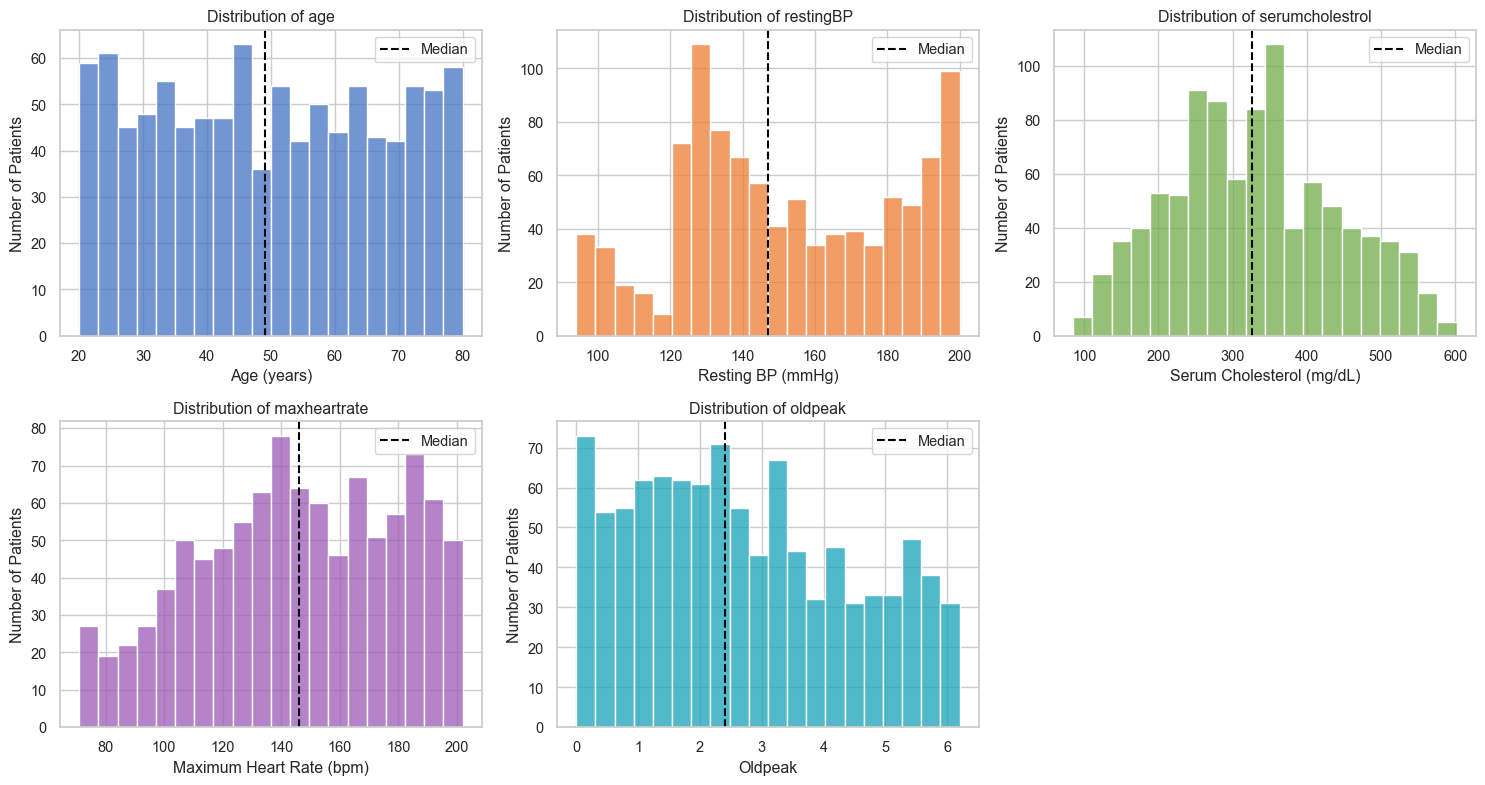

In [63]:
# Colors for each numerical feature
colors = ["#4472C4", "#ED7D31", "#70AD47",
          "#9B59B6", "#17A2B8"]

# Readable feature labels
labels = ["Age (years)", "Resting BP (mmHg)",
          "Serum Cholesterol (mg/dL)",
          "Maximum Heart Rate (bpm)", "Oldpeak"]

# Create histograms in a 2x3 layout
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(numerical):
    ax = axes.flat[i]

    # Plot histogram for each feature
    sns.histplot(
        cleaned[col].dropna(),
        bins=20,
        color=colors[i],
        edgecolor="white",
        ax=ax
    )

    # Add median reference line
    ax.axvline(
        cleaned[col].median(),
        color="black",
        linestyle="--",
        label="Median"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(labels[i])
    ax.set_ylabel("Number of Patients")
    ax.legend()

# Remove the empty subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

Histograms were generated to examine the distribution and spread of the five numerical features. Median reference lines were included to highlight the center of each distribution. The cholesterol histogram excludes the 53 missing measurements, ensuring that invalid zero values do not distort the observed distribution.

## Outlier Detection

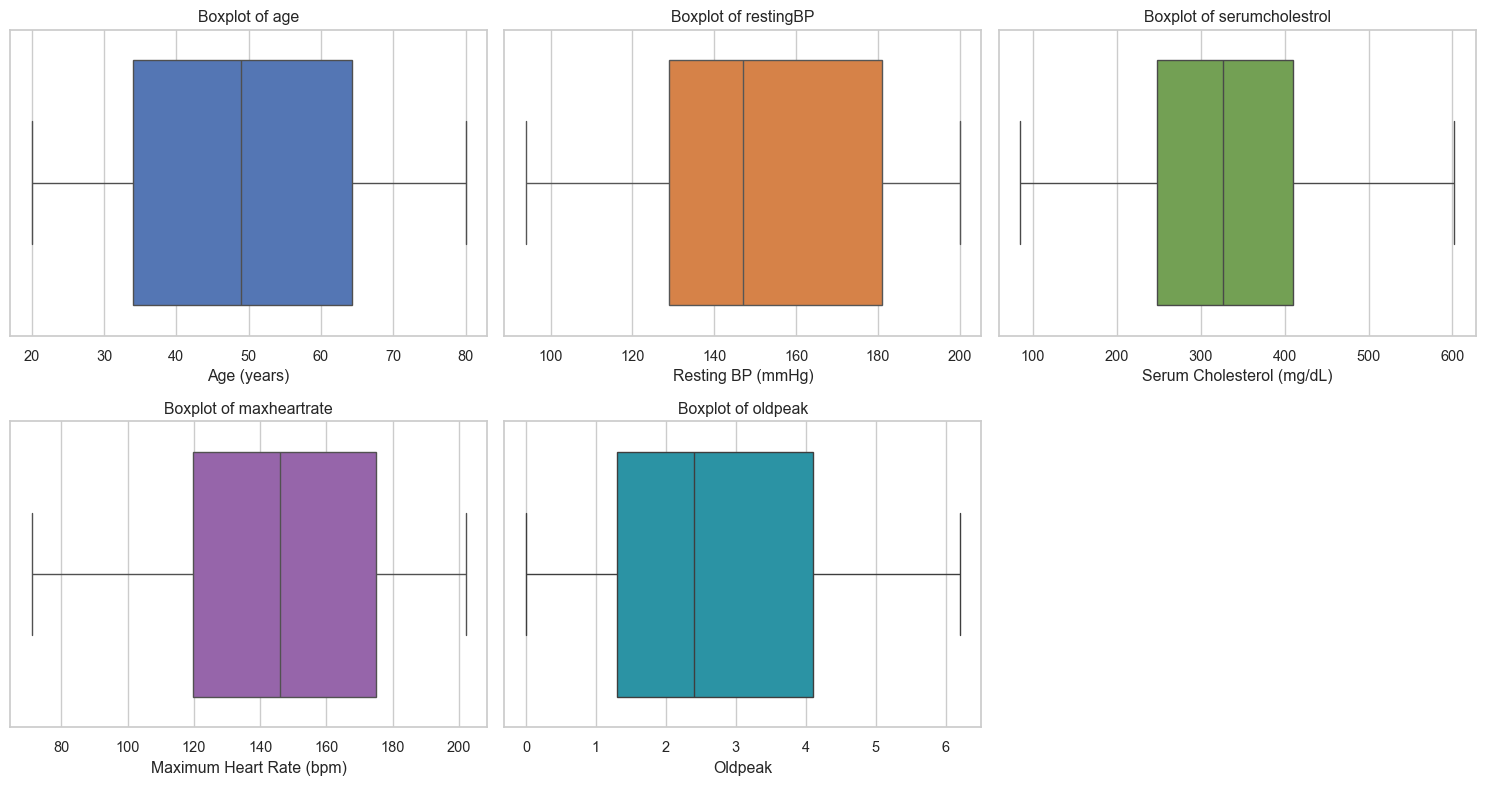

In [64]:
# Create boxplots for numerical features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(numerical):
    ax = axes.flat[i]

    # Create boxplot using the same feature color
    sns.boxplot(
        x=cleaned[col],
        color=colors[i],
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(labels[i])

# Remove the empty subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

In [84]:
# Store outlier counts for each feature
outlier_results = []

for col in numerical:

    # Calculate quartiles and IQR
    Q1 = cleaned[col].quantile(0.25)
    Q3 = cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    # Calculate lower and upper bounds
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Count observations outside the bounds
    count = (
        (cleaned[col] < lower) |
        (cleaned[col] > upper)
    ).sum()

    outlier_results.append([col, count])

# Create and display results table
outlier_table = pd.DataFrame(
    outlier_results,
    columns=["Feature", "Outlier Count"]
)

display(
    outlier_table.style.hide(axis="index")
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#F2F2F2"),
            ("color", "black"), ("text-align", "left"),
            ("padding", "10px")
        ]},
        {"selector": "td", "props": [
            ("color", "black"), ("text-align", "left"),
            ("padding", "8px")
        ]}
    ])
)

Feature,Outlier Count
age,0
restingBP,0
serumcholestrol,0
maxheartrate,0
oldpeak,0


Boxplots and the 1.5 × IQR method were used to identify potential outliers across the numerical features. No statistical outliers were detected using this method. However, 12 cholesterol measurements remain outside the data dictionary's documented range. These values were retained because unusual clinical measurements do not necessarily indicate data errors.

## Categorical Feature Distributions

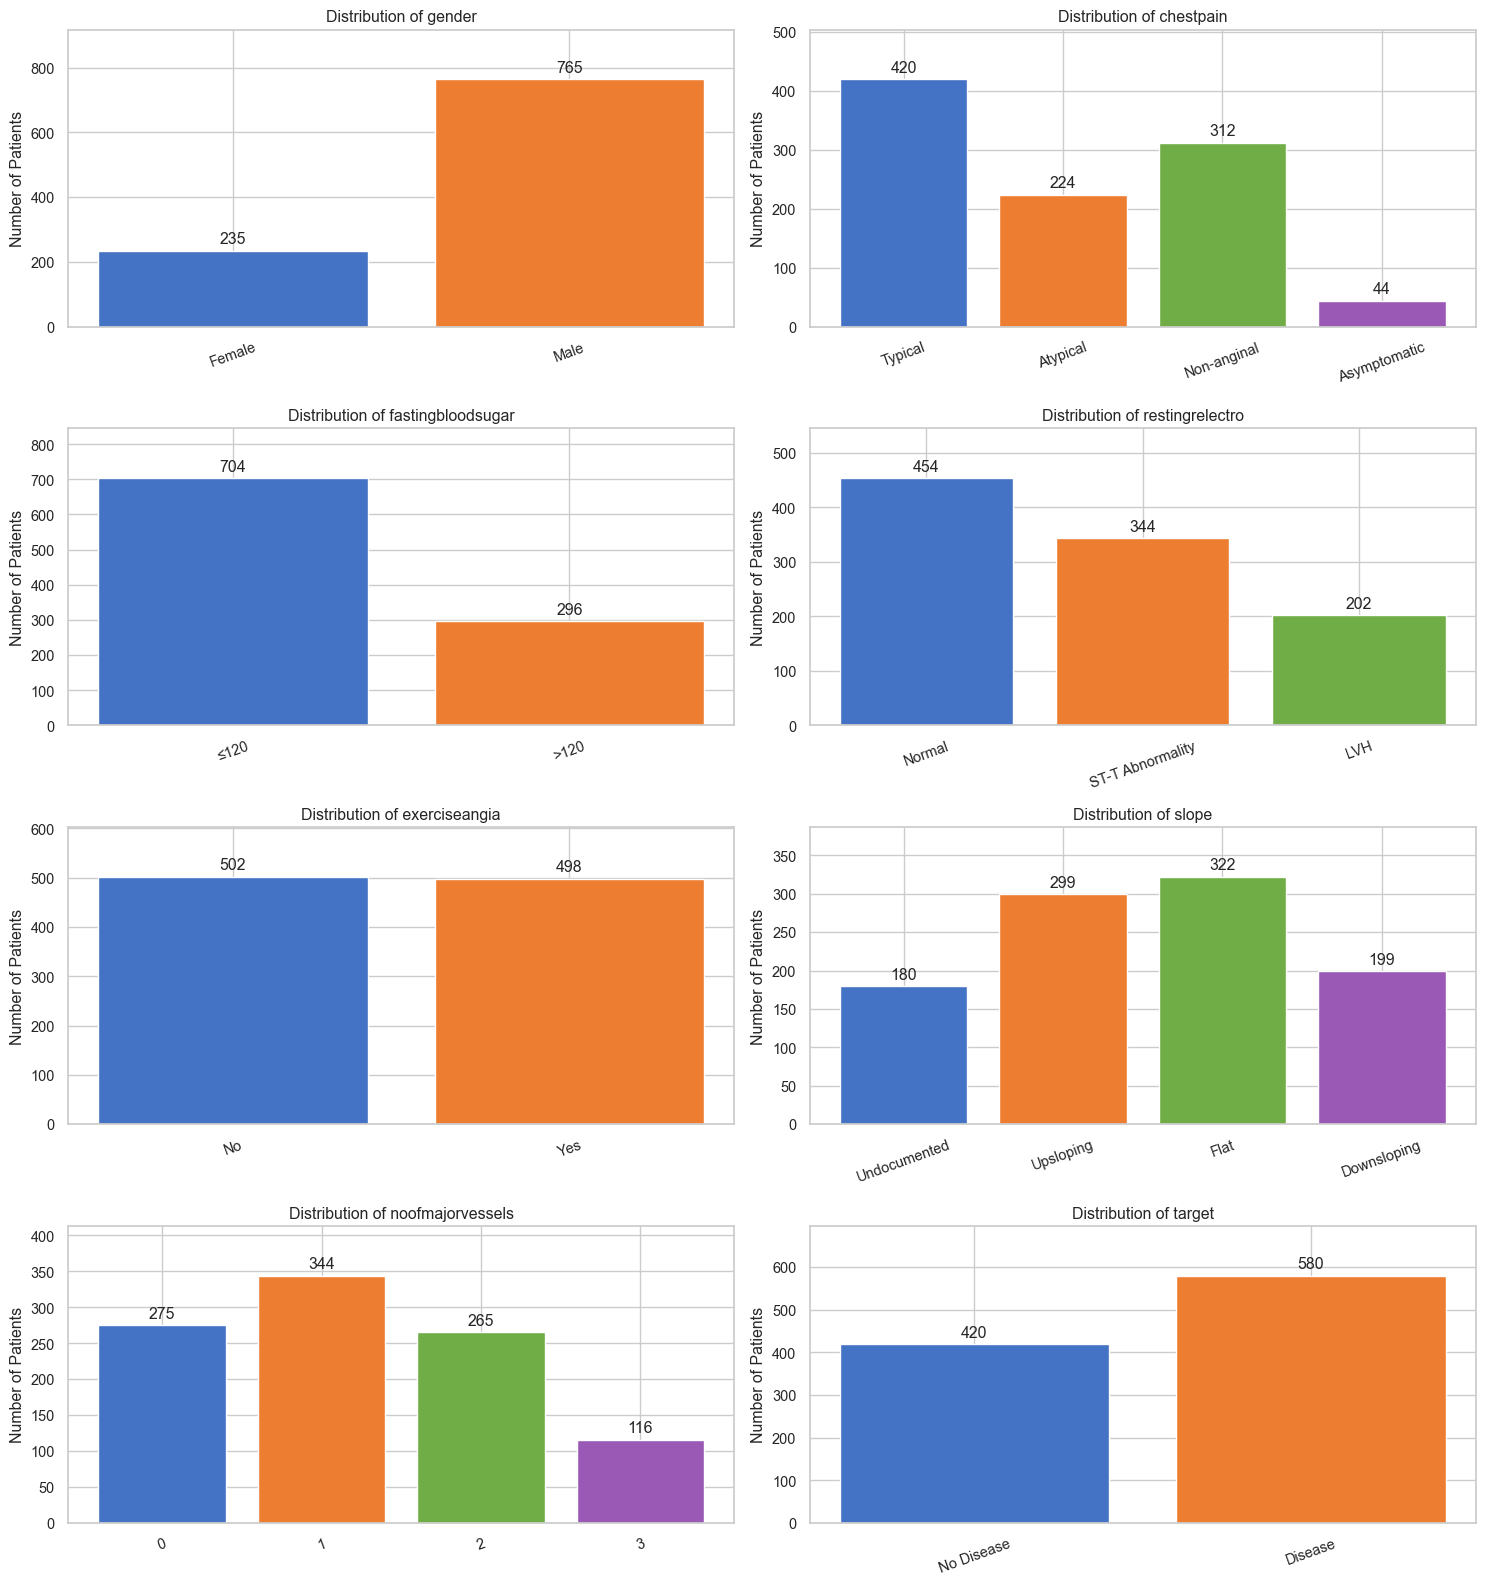

In [66]:
# Define readable labels for categorical features
category_labels = {
    "gender": {0: "Female", 1: "Male"},

    "chestpain": {
        0: "Typical", 1: "Atypical",
        2: "Non-anginal", 3: "Asymptomatic"
    },

    "fastingbloodsugar": {
        0: "≤120", 1: ">120"
    },

    "restingrelectro": {
        0: "Normal", 1: "ST-T Abnormality", 2: "LVH"
    },

    "exerciseangia": {0: "No", 1: "Yes"},

    "slope": {
        0: "Undocumented", 1: "Upsloping",
        2: "Flat", 3: "Downsloping"
    },

    "noofmajorvessels": {
        0: "0", 1: "1", 2: "2", 3: "3"
    },

    "target": {
        0: "No Disease", 1: "Disease"
    }
}

# Assign different colors to categories
bar_colors = ["#4472C4", "#ED7D31",
              "#70AD47", "#9B59B6"]

# Create a 4x2 grid of categorical plots
fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for ax, (col, mapping) in zip(axes.flat, category_labels.items()):

    # Count each category in the original code order
    counts = cleaned[col].map(mapping).value_counts()
    counts = counts.reindex(list(mapping.values()), fill_value=0)

    # Plot category frequencies
    bars = ax.bar(
        counts.index,
        counts.values,
        color=bar_colors[:len(counts)],
        edgecolor="white"
    )

    # Add counts above each bar
    ax.bar_label(bars, padding=3)

    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Number of Patients")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, counts.max() * 1.2)

plt.tight_layout()
plt.show()

Categorical distributions were examined to understand the composition of the dataset. Male patients account for 76.5% of observations, and typical angina is the most frequently recorded chest pain type (42%). Exercise-induced angina is nearly evenly distributed, while the target variable contains 58% patients with heart disease and 42% without. The undocumented slope category accounts for 18% of records and requires further verification.

## Saving the Cleaned Dataset

In [68]:
# Save the cleaned dataset for further EDA
output_path = Path("../datasets/cleaned/cardiovascular_cleaned.csv")

cleaned.to_csv(output_path, index=False)

# Verify the final dataset
print("Cleaned dataset saved successfully!")
print("Final dataset shape:", cleaned.shape)
print("Total patients retained:", len(cleaned))
print("Missing cholesterol values:",
      cleaned["serumcholestrol"].isna().sum())

Cleaned dataset saved successfully!
Final dataset shape: (1000, 15)
Total patients retained: 1000
Missing cholesterol values: 53


## Age Group Distribution

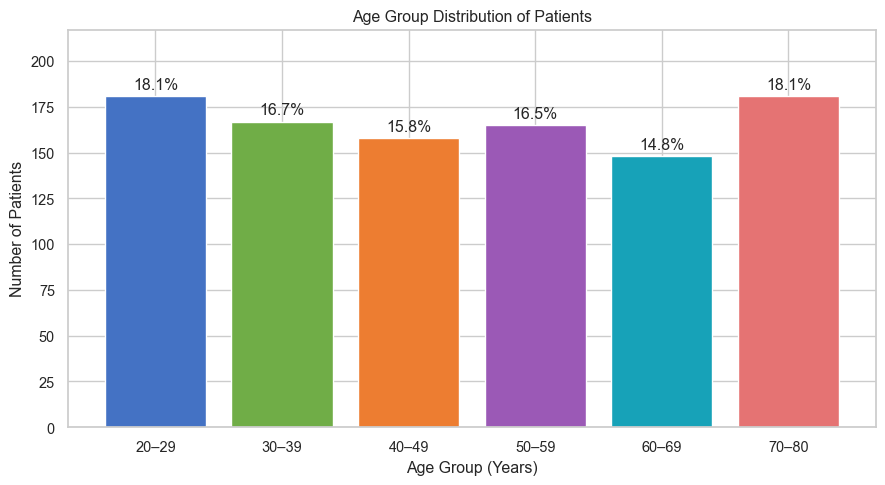

In [69]:
# Divide patients into age groups
age_groups = pd.cut(
    cleaned["age"],
    bins=[19, 29, 39, 49, 59, 69, 80],
    labels=["20–29", "30–39", "40–49",
            "50–59", "60–69", "70–80"]
)

# Count patients in each age group
age_counts = age_groups.value_counts().sort_index()

# Create a bar chart with distinct colors
plt.figure(figsize=(9, 5))

bars = plt.bar(
    age_counts.index,
    age_counts.values,
    color=["#4472C4", "#70AD47", "#ED7D31",
           "#9B59B6", "#17A2B8", "#E57373"],
    edgecolor="white"
)

# Display percentage above each bar
percentages = age_counts / len(cleaned) * 100
plt.bar_label(
    bars,
    labels=[f"{p:.1f}%" for p in percentages],
    padding=3
)

plt.title("Age Group Distribution of Patients")
plt.xlabel("Age Group (Years)")
plt.ylabel("Number of Patients")
plt.ylim(0, age_counts.max() * 1.2)

plt.tight_layout()
plt.show()

Patients are relatively evenly distributed across the six age groups, with the 20–29 and 70–80 age groups each representing 18.1% of the dataset. The 60–69 age group has the lowest representation at 14.8%. This suggests that the dataset includes patients across a broad age range without a strong concentration in any single age group.

## Missing Cholesterol Pattern

In [85]:
# Calculate cholesterol missingness within each target group
missing_summary = cleaned.groupby("target")[
    "cholesterol_missing"
].agg(["size", "sum"])

# Rename columns
missing_summary.columns = ["Total Patients", "Missing Cholesterol"]

# Calculate percentage missing within each group
missing_summary["Missing (%)"] = (
    missing_summary["Missing Cholesterol"] /
    missing_summary["Total Patients"] * 100
).round(2)

# Label the target groups
missing_summary.index = ["No Heart Disease", "Heart Disease"]

# Display formatted table
display(
    missing_summary.style
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#F2F2F2"),
            ("color", "black"), ("text-align", "left"),
            ("padding", "10px")
        ]},
        {"selector": "td", "props": [
            ("color", "black"), ("text-align", "left"),
            ("padding", "8px")
        ]}
    ])
)

,Total Patients,Missing Cholesterol,Missing (%)
No Heart Disease,420,0,0.000000
Heart Disease,580,53,9.140000


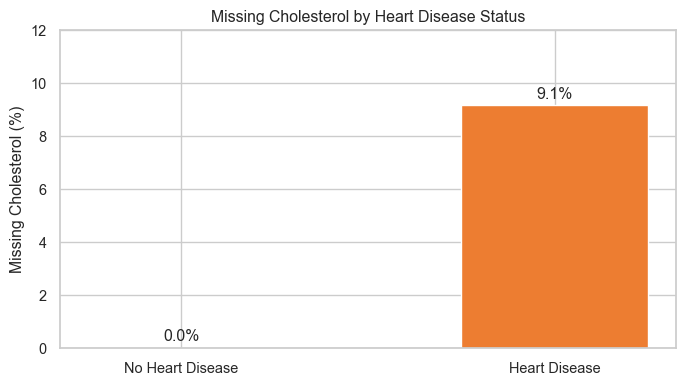

In [72]:
# Visualize cholesterol missingness by target group
plt.figure(figsize=(7, 4))

bars = plt.bar(
    missing_summary.index,
    missing_summary["Missing (%)"],
    color=["#4472C4", "#ED7D31"],
    width=0.5
)

# Add percentage labels
plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Missing Cholesterol by Heart Disease Status")
plt.ylabel("Missing Cholesterol (%)")
plt.ylim(0, 12)

plt.tight_layout()
plt.show()

Missing cholesterol measurements were examined across the two heart disease classifications. All 53 missing cholesterol values belong to patients classified as having heart disease, representing 9.14% of that group. No cholesterol measurements are missing among patients without heart disease.